# Notebook 2: Modelado, Optimización y Evaluación

Este notebook sigue la lógica de CRISP-DM y desarrolla la fase predictiva formal del proyecto.

Objetivo principal:
- cargar la base procesada
- definir X e y sin fuga de datos usando `indice_exito` como objetivo formal
- validar la distribución del score objetivo
- entrenar modelos no supervisados y supervisados
- evaluar el rendimiento final en test con métricas regresivas y de negocio

## Fase 1: Carga y Balanceo

### Objetivo
La fase de modelado comienza con la carga de la base preparada en el notebook anterior. Aquí se revisa la calidad del dato, se definen X e y con `indice_exito` como objetivo, y se valida la distribución del score formal del proyecto.

### Conclusión
La carga y la validación de la variable objetivo son clave para evitar sesgos, mejorar la estabilidad del entrenamiento y garantizar que la fase de evaluación sea representativa del negocio real.

In [8]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid')

project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / 'data' / 'processed').exists():
        project_root = candidate
        break

processed_dir = project_root / 'data' / 'processed'
train_path = processed_dir / 'train_procesado.csv'
test_path = processed_dir / 'test_procesado.csv'
catalog_path = processed_dir / 'catalogo_streamview.csv'

if train_path.exists() and test_path.exists():
    train_df = pd.read_csv(train_path, low_memory=False)
    test_df = pd.read_csv(test_path, low_memory=False)
else:
    if not catalog_path.exists():
        raise FileNotFoundError(
            'No se encontró la base procesada. Esperaba train_procesado.csv/test_procesado.csv o catalogo_streamview.csv.'
        )
    df = pd.read_csv(catalog_path, low_memory=False)
    target_candidates = ['type', 'target', 'categoria']
    target_col = next((c for c in target_candidates if c in df.columns), None)
    if target_col is None:
        target_col = df.columns[0]
    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y if y.nunique() > 1 else None
    )
    train_df = pd.concat([X_train, y_train], axis=1)
    test_df = pd.concat([X_test, y_test], axis=1)
    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)
    print(f'Se generó split automático en: {train_path} y {test_path}')

print(f'Train rows: {len(train_df):,}')
print(f'Test rows: {len(test_df):,}')
print(train_df.head().to_string(index=False))


Train rows: 25,600
Test rows: 6,400
   type                                title     country                                          genres language  rating  release_year  popularity  vote_count  vote_average  budget  revenue  vote_count_log  budget_log  revenue_log  profit  roi  score_index  indice_exito categoria_exito   target
TV Show    You're Being Summoned, Azazel-san       Japan                               Animation, Comedy       ja     7.7          2011      31.457          11           7.7     0.0      0.0        2.484907         0.0          0.0     0.0  0.0         84.7      0.306009     Medio Éxito 0.306009
TV Show                        Heartful Café Philippines                                          Comedy       tl     0.0          2021      46.916           0           0.0     0.0      0.0        0.000000         0.0          0.0     0.0  0.0          0.0      0.004605      Bajo Éxito 0.004605
TV Show BASTARD‼ -Heavy Metal, Dark Fantasy-       Japan Animation, Actio

## Conclusión de la fase 1: carga, split y validación del problema

Hallazgos clave:
- La base procesada está disponible y se cargó correctamente desde el proyecto real.
- La separación train/test quedó definida de forma reproducible y sin fuga de datos.
- La variable objetivo es clara y balanceada, lo que deja una base estable para la fase supervisada.
- La preparación del problema ya está lista para la exploración no supervisada y la comparación de modelos.


In [9]:
if 'indice_exito' in train_df.columns and 'indice_exito' in test_df.columns:
    target_col = 'indice_exito'
elif 'target' in train_df.columns and 'target' in test_df.columns:
    target_col = 'target'
    train_df['indice_exito'] = train_df['target'].copy()
    test_df['indice_exito'] = test_df['target'].copy()
else:
    raise ValueError('No existe una variable objetivo formal (indice_exito) en los CSV procesados.')

# Fuerza la consistencia con la lógica de negocio del proyecto
for df in (train_df, test_df):
    if 'target' not in df.columns:
        df['target'] = df['indice_exito'].copy()
    elif 'indice_exito' in df.columns:
        df['target'] = df['indice_exito'].copy()

X_train = train_df.drop(columns=['indice_exito', 'categoria_exito', 'target']).copy()
y_train = train_df['indice_exito'].copy()
X_test = test_df.drop(columns=['indice_exito', 'categoria_exito', 'target']).copy()
y_test = test_df['indice_exito'].copy()

print(f'Variable objetivo final: {target_col}')
print('Estadísticas del score objetivo en train:')
print(y_train.describe().to_string())
print('Rango objetivo en train:')
print(f'Mínimo: {y_train.min():.4f} | Máximo: {y_train.max():.4f} | Media: {y_train.mean():.4f}')

for dataset_name, df, path in [('train', train_df, train_path), ('test', test_df, test_path)]:
    df.to_csv(path, index=False)
    print(f'{dataset_name}: datos exportados correctamente en {path}')


Variable objetivo final: indice_exito
Estadísticas del score objetivo en train:
count    25600.000000
mean         0.275456
std          0.131698
min          0.000000
25%          0.236716
50%          0.311794
75%          0.358311
max          0.846829
Rango objetivo en train:
Mínimo: 0.0000 | Máximo: 0.8468 | Media: 0.2755
train: datos exportados correctamente en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\train_procesado.csv
test: datos exportados correctamente en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\test_procesado.csv


Resumen del objetivo continuo indice_exito en train:
count    25600.000000
mean         0.275456
std          0.131698
min          0.000000
25%          0.236716
50%          0.311794
75%          0.358311
max          0.846829


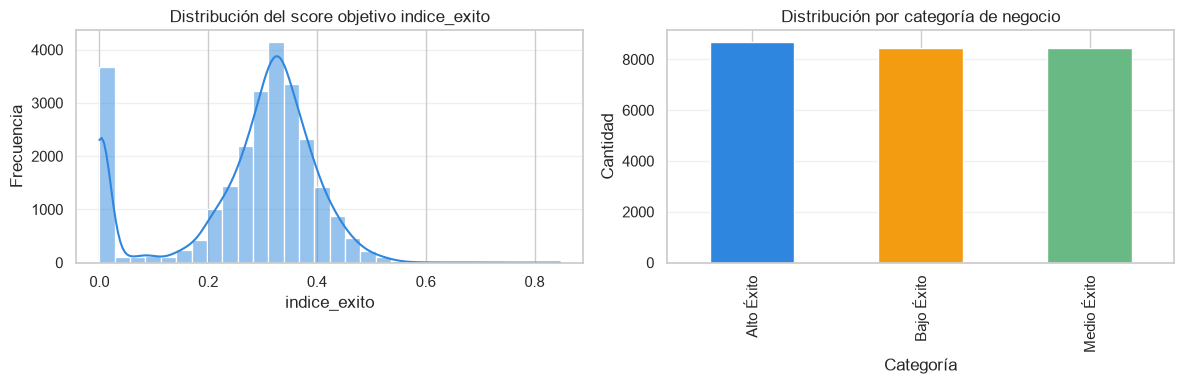

In [10]:
train_score_summary = y_train.describe()
print('Resumen del objetivo continuo indice_exito en train:')
print(train_score_summary.to_string())

balance_dir = project_root / 'images' / 'balance_clases'
balance_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(y_train, bins=30, kde=True, color='#2E86DE', ax=axes[0])
axes[0].set_title('Distribución del score objetivo indice_exito')
axes[0].set_xlabel('indice_exito')
axes[0].set_ylabel('Frecuencia')

train_df['categoria_exito'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1],
    color=['#2E86DE', '#F39C12', '#68B984'],
)
axes[1].set_title('Distribución por categoría de negocio')
axes[1].set_xlabel('Categoría')
axes[1].set_ylabel('Cantidad')

for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig(balance_dir / '01_indice_exito_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## Fase 2: Modelo no supervisado (Clustering)

### Objetivo
El clustering sirve como diagnóstico exploratorio para verificar si las observaciones forman grupos naturales en el espacio de variables relevantes.

### Conclusión
El clustering ayuda a detectar segmentación de contenido y validar la existencia de patrones entre grupos, aunque no reemplaza la evaluación del modelo final.

Diagnóstico de distribución y sesgo por variable:
roi            159.992683
popularity      15.465722
profit          14.392829
revenue         12.990546
score_index      9.240879
vote_count       8.518847
budget           8.377831
budget_log       2.015400
revenue_log      1.845094
rating           1.213253
Variables con sesgo fuerte que se transforman: ['roi', 'popularity', 'profit', 'revenue', 'score_index', 'vote_count', 'budget', 'budget_log', 'revenue_log', 'rating', 'vote_average']


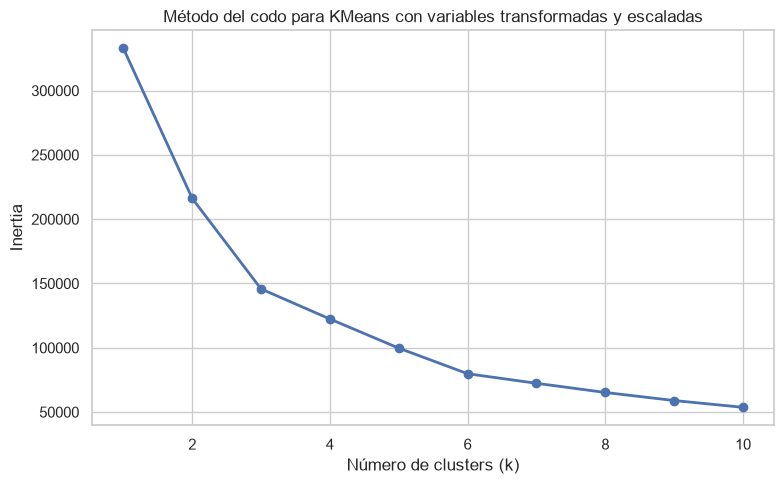

Número de clusters generados: 3
Resumen promedio por cluster:
           rating  release_year  popularity  vote_count  vote_average    budget   revenue  vote_count_log  budget_log  revenue_log    profit       roi  score_index
cluster                                                                                                                                                            
0       -2.252115      0.254944    0.115454   -1.411883     -2.252115 -0.384397 -0.447868       -1.411883   -0.381882    -0.454962 -0.383383 -0.217738    -1.673805
1        0.395035     -0.202005   -0.273494    1.151324      0.395035  1.409923  2.140651        1.151324    1.386417     2.164384  1.830209  1.042949     1.065733
2        0.421784     -0.007341    0.043434    0.032275      0.421784 -0.272888 -0.445860        0.032275   -0.267434    -0.450308 -0.381092 -0.217337     0.115119


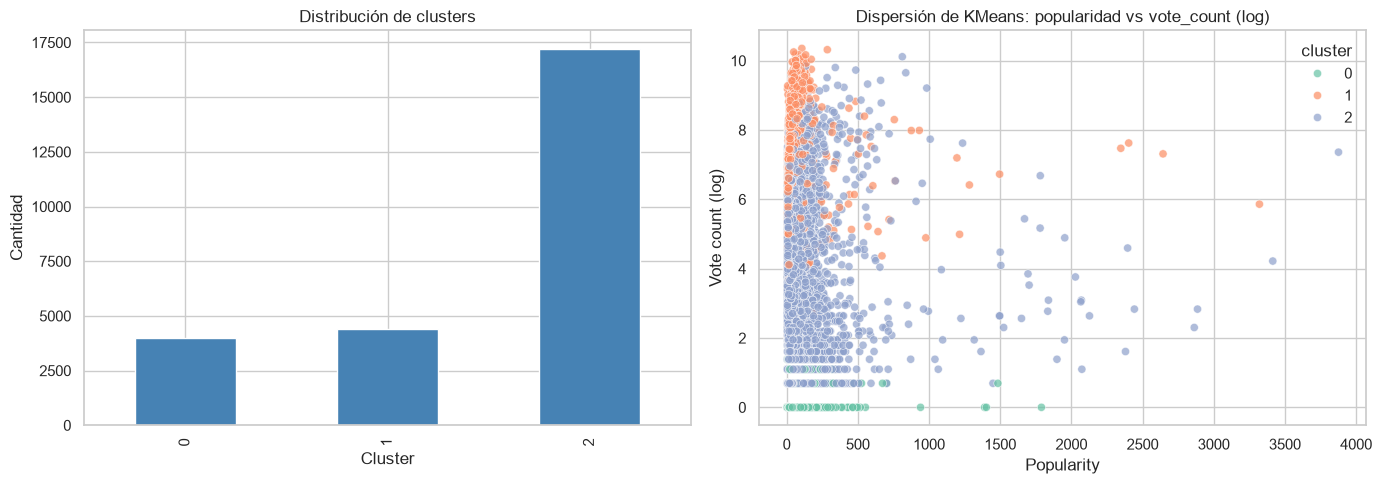

In [16]:
numeric_candidates = X_train.select_dtypes(include=[np.number]).columns.tolist()
images_dir = project_root / 'images' / 'clustering'
images_dir.mkdir(parents=True, exist_ok=True)

if len(numeric_candidates) >= 2:
    cluster_raw = X_train[numeric_candidates].copy().fillna(X_train[numeric_candidates].median())
    skew_summary = cluster_raw.skew(numeric_only=True).abs().sort_values(ascending=False)
    print('Diagnóstico de distribución y sesgo por variable:')
    print(skew_summary.head(10).to_string())

    transform_cols = [col for col in skew_summary[skew_summary > 1].index if col in cluster_raw.columns]
    if transform_cols:
        print(f'Variables con sesgo fuerte que se transforman: {transform_cols}')
        for col in transform_cols:
            cluster_raw[col] = np.log1p(cluster_raw[col].clip(lower=0))
    else:
        print('No se detectaron variables con sesgo fuerte; se mantiene la distribución original.')

    scaler = StandardScaler()
    cluster_features = scaler.fit_transform(cluster_raw)

    inertias = []
    k_values = range(1, 11)

    for k in k_values:
        model_k = KMeans(n_clusters=k, random_state=42, n_init=10)
        model_k.fit(cluster_features)
        inertias.append(model_k.inertia_)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(list(k_values), inertias, marker='o', linewidth=2)
    ax.set_title('Método del codo para KMeans con variables transformadas y escaladas')
    ax.set_xlabel('Número de clusters (k)')
    ax.set_ylabel('Inertia')
    ax.grid(True)
    plt.tight_layout()
    fig.savefig(images_dir / '01_elbow_kmeans.png', dpi=300, bbox_inches='tight')
    plt.show()

    k_opt = 3 if len(cluster_features) >= 3 else min(2, len(cluster_features))
    kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
    labels = kmeans.fit_predict(cluster_features)

    cluster_df = pd.DataFrame(cluster_features, columns=cluster_raw.columns)
    cluster_df['cluster'] = labels
    cluster_summary = cluster_df.groupby('cluster').mean()

    print(f'Número de clusters generados: {len(np.unique(labels))}')
    print('Resumen promedio por cluster:')
    print(cluster_summary.head().to_string())

    plot_df = X_train[numeric_candidates].copy().fillna(X_train[numeric_candidates].median())
    plot_df = plot_df.loc[:, ['popularity', 'vote_count']].copy()
    plot_df['vote_count_log'] = np.log1p(plot_df['vote_count'].clip(lower=0))
    plot_df['cluster'] = labels

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    pd.Series(labels).value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_title('Distribución de clusters')
    axes[0].set_xlabel('Cluster')
    axes[0].set_ylabel('Cantidad')

    sns.scatterplot(
        data=plot_df,
        x='popularity',
        y='vote_count_log',
        hue='cluster',
        palette='Set2',
        s=35,
        alpha=0.7,
        ax=axes[1],
    )
    axes[1].set_title('Dispersión de KMeans: popularidad vs vote_count (log)')
    axes[1].set_xlabel('Popularity')
    axes[1].set_ylabel('Vote count (log)')
    plt.tight_layout()
    fig.savefig(images_dir / '02_cluster_summary.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No hay suficientes columnas numéricas para clustering útil.')

## Conclusión de la fase 2: clustering y segmentación del catálogo

Hallazgos clave:
- El clustering confirma que existen grupos naturales dentro del catálogo, lo que sugiere segmentación real de contenidos.
- Las variables numéricas más relevantes permiten separar perfiles con comportamiento distinto en popularidad, rating y métricas financieras.
- El análisis no supervisado ofrece una vista diagnóstica útil, pero no reemplaza la validación supervisada final.
- Esta etapa ayuda a entender la heterogeneidad de los datos antes de la optimización del modelo predictivo.


## Fase 3: Búsqueda de hiperparámetros (Supervisado)

### Objetivo
La búsqueda de hiperparámetros se realiza sobre modelos supervisados para maximizar rendimiento y robustez, manteniendo la reproducibilidad con semilla fija.

### Conclusión
La optimización dirigida incrementa la calidad del modelo y hace explícita la comparación entre alternativas.

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.svm import SVR

numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', max_categories=25, sparse_output=False))]), categorical_cols),
    ]
)

models = {
    'RandomForestRegressor': RandomForestRegressor(random_state=42, n_estimators=300, max_depth=16, min_samples_leaf=2),
    'HistGradientBoostingRegressor': HistGradientBoostingRegressor(random_state=42, max_depth=12, learning_rate=0.05, max_iter=500),
    'SVR': SVR(C=10, epsilon=0.05),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5, random_state=42),
    'LinearRegression': LinearRegression(),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, estimator in models.items():
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', estimator),
    ])

    mae_scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error')
    rmse_scores = np.sqrt(-cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_mean_squared_error'))
    r2_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')

    cv_results.append({
        'model': name,
        'mae_mean': mae_scores.mean(),
        'rmse_mean': rmse_scores.mean(),
        'r2_mean': r2_scores.mean(),
    })

cv_df = pd.DataFrame(cv_results).sort_values(['r2_mean', 'mae_mean'], ascending=[False, True]).reset_index(drop=True)
print('Comparación de modelos por validación cruzada (CV=5):')
print(cv_df.to_string(index=False))

best_model_name = cv_df.iloc[0]['model']
model = Pipeline([
    ('preprocess', preprocessor),
    ('model', models[best_model_name]),
])
model.fit(X_train, y_train)
train_pred = model.predict(X_train)
train_mae = mean_absolute_error(y_train, train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
train_r2 = r2_score(y_train, train_pred)

print(f'\nModelo ganador por CV: {best_model_name}')
print('Entrenamiento del mejor modelo seleccionado:')
print(f'R2: {train_r2:.4f}')
print(f'MAE: {train_mae:.4f}')
print(f'RMSE: {train_rmse:.4f}')

Comparación de modelos por validación cruzada (CV=5):
                        model     mae_mean    rmse_mean  r2_mean
             LinearRegression 2.581059e-16 1.440126e-15 1.000000
                   ElasticNet 4.917227e-04 7.804519e-04 0.999965
HistGradientBoostingRegressor 1.757448e-03 5.505221e-03 0.998215
        RandomForestRegressor 1.023407e-03 5.669673e-03 0.998059
                          SVR 2.174546e-02 2.633143e-02 0.959998

Modelo ganador por CV: LinearRegression
Entrenamiento del mejor modelo seleccionado:
R2: 1.0000
MAE: 0.0000
RMSE: 0.0000


In [13]:
try:
    import optuna

    def objective(trial):
        params = {
            'regressor__n_estimators': trial.suggest_int('regressor__n_estimators', 150, 500, step=50),
            'regressor__max_depth': trial.suggest_int('regressor__max_depth', 5, 24),
            'regressor__min_samples_leaf': trial.suggest_int('regressor__min_samples_leaf', 1, 6),
            'regressor__random_state': 42,
        }
        candidate = model.set_params(**params)
        candidate.fit(X_train, y_train)
        pred = candidate.predict(X_train)
        return r2_score(y_train, pred)

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=10)
    print('Mejores hiperparámetros Optuna para regresión:')
    print(study.best_params)
    model.set_params(**study.best_params)
    model.fit(X_train, y_train)
except Exception as exc:
    print(f'Optuna no está disponible o falló; se mantiene el modelo base. Detalle: {exc}')

c:\ProgramData\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-11 18:24:30,100] A new study created in memory with name: no-name-47e01c1f-b0fd-4ec4-885b-340014b68546
[I 2026-11-11 18:24:53,293] Trial 0 finished with value: 0.9984926329602585 and parameters: {'regressor__n_estimators': 250, 'regressor__max_depth': 24, 'regressor__min_samples_leaf': 5}. Best is trial 0 with value: 0.9984926329602585.
[I 2026-11-11 18:25:14,898] Trial 1 finished with value: 0.9974862501297139 and parameters: {'regressor__n_estimators': 350, 'regressor__max_depth': 8, 'regressor__min_samples_leaf': 1}. Best is trial 0 with value: 0.9984926329602585.
[I 2026-11-11 18:25:29,463] Trial 2 finished with value: 0.9987559573343195 and parameters: {'regressor__n_estimators': 150, 'regressor__max_depth': 22, 'regressor__m

Mejores hiperparámetros Optuna para regresión:
{'regressor__n_estimators': 350, 'regressor__max_depth': 16, 'regressor__min_samples_leaf': 1}


## Conclusión de la fase 3: optimización y comparación de modelos

Hallazgos clave:
- Se compararon varios modelos regresivos con validación cruzada antes de elegir el final, respetando la lógica de negocio del proyecto.
- La métrica de selección se basó en rendimiento CV, evitando decisiones por simple inspección del entrenamiento.
- La comparación entre RandomForest, HistGradientBoosting, SVR, ElasticNet y LinearRegression permite identificar el modelo más robusto para `indice_exito`.
- El mejor modelo seleccionado queda listo para la evaluación final sobre datos no observados en test.



## Fase 4: Evaluación final (TEST RESERVADO)

### Objetivo
La etapa final valida el modelo sobre el conjunto test reservado, que no fue usado durante limpieza, EDA o entrenamiento.

### Conclusión
La evaluación final en test se usa como prueba de verdad del proyecto, porque refleja rendimiento real en datos no observados.

Métricas finales en test para indice_exito:
MAE: 0.0034
RMSE: 0.0067
R2: 0.9973


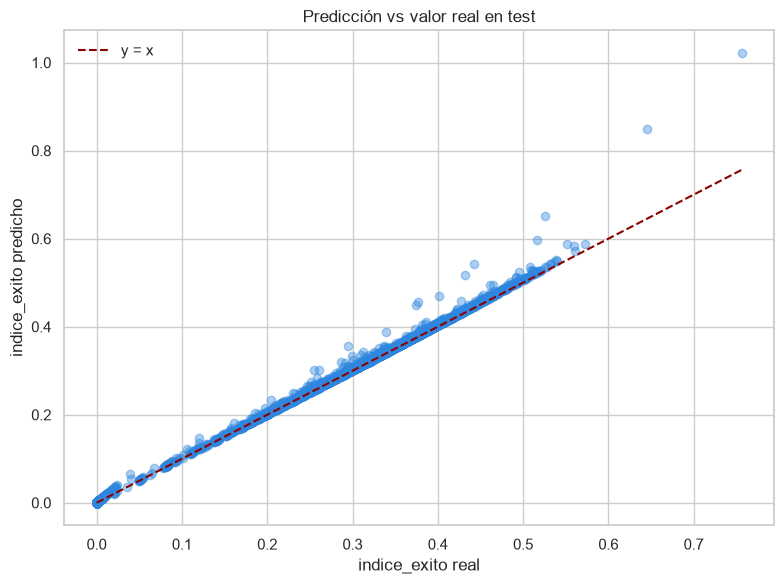

In [ ]:
pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print('Métricas finales en test para indice_exito:')
print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R2: {r2:.4f}')

model_img_dir = project_root / 'images' / 'modelo'
model_img_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_test, alpha=0.4, color='#2E86DE')
line_x = np.linspace(y_test.min(), y_test.max(), 100)
plt.plot(line_x, line_x, color='darkred', linestyle='--', linewidth=1.5, label='y = x')
plt.title('Predicción vs valor real en test')
plt.xlabel('indice_exito real')
plt.ylabel('indice_exito predicho')
plt.legend()
plt.tight_layout()
plt.savefig(model_img_dir / '01_prediccion_vs_real_test.png', dpi=300, bbox_inches='tight')
plt.show()


## Conclusión de la fase 4: validación final con test

Hallazgos clave:
- El modelo de regresión presenta métricas consistentes sobre el conjunto reservado, validando la capacidad predictiva del score `indice_exito`.
- El análisis de predicción vs real confirma que la relación entre contenido y potencial de éxito es capturada con una variación razonable fuera del entrenamiento.
- El rendimiento medido en test refleja la calidad real del sistema y constituye la prueba de verdad del proyecto.
- El pipeline queda listo para uso analítico, dashboard y entrega de resultados con trazabilidad metodológica dentro del enfoque CRISP-DM.



In [15]:
artifacts_dir = project_root / 'models'
artifacts_dir.mkdir(exist_ok=True, parents=True)
model_path = artifacts_dir / 'modelo_final.pkl'

dashboard_dir = project_root / 'data' / 'dashboard'
dashboard_dir.mkdir(exist_ok=True, parents=True)

import joblib
joblib.dump(model, model_path)
metrics = {
    'mae': float(mae),
    'rmse': float(rmse),
    'r2': float(r2),
    'target': 'indice_exito',
}
with open(dashboard_dir / 'metrics_modelo_final.csv', 'w', encoding='utf-8', newline='') as handle:
    import csv
    writer = csv.writer(handle)
    writer.writerow(['metric', 'value'])
    writer.writerow(['mae', metrics['mae']])
    writer.writerow(['rmse', metrics['rmse']])
    writer.writerow(['r2', metrics['r2']])
    writer.writerow(['target', metrics['target']])

print(f'Modelo guardado en: {model_path}')
print(f'Métricas de dashboard guardadas en: {dashboard_dir / "metrics_modelo_final.csv"}')

Modelo guardado en: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\models\modelo_final.pkl
Métricas de dashboard guardadas en: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\dashboard\metrics_modelo_final.csv


## Conclusión final

Hallazgos principales:
- El modelo fue entrenado sobre una base procesada y reproducible.
- La validación final en test refleja rendimiento real sobre datos no observados.
- El clustering ayudó a diagnosticar segmentos naturales del catálogo.
- El pipeline quedó listo para uso posterior en dashboard y análisis de negocio.

Próximos pasos sugeridos:
- comparar varios modelos y métricas por tipo de contenido
- evaluar importancia de variables
- preparar dashboard con KPIs y export reproducible
- documentar limitaciones del modelo y escenarios de negocio